# 05 — O vencedor do Challenge (HearHeart) vs a nossa CNN

Para saber se a nossa CNN está ao nível do estado da arte, reimplementámos o modelo que **ganhou o PhysioNet
Challenge 2022** (equipa HearHeart, Lu et al., WA 0.780 no teste escondido; `literature/02_*`) a partir do código
oficial (`src/hearheart.py`) e treinámo-lo **com os nossos folds e a nossa avaliação**. Os números publicados no
Challenge vêm de um teste escondido e não se comparam diretamente com os nossos.

A rede deles é uma CNN ainda mais pequena do que a nossa (~38 mil parâmetros): 4 convoluções 3×3 com stride 1
(32-32-32-64 mapas), BatchNorm, ReLU, 2 max pooling, dropout 0.1, *global average pooling* e uma camada linear.

Duas versões, para separar dois efeitos:

| Versão | Pasta | O que é | Pergunta |
|---|---|---|---|
| **B — só a rede** | `results/experiments/hearheart_arch` | a rede deles com a **nossa** entrada (4 s, 40 mel) e o **nosso** treino | a arquitetura deles é melhor do que a nossa? |
| **A — receita completa** | `results/experiments/hearheart` | segmentos de 15 s, 128 mel até 2 kHz, ruído a 15 dB, pesos de classe 5/3/1, descida da lr, paragem pela WA, 6 features espectrais num 2.º ramo (sem idade/sexo/gravidez: só usamos o áudio) | a entrada e o treino deles são melhores do que os nossos? |

Os modelos foram treinados no Deucalion (`scripts/deucalion_hearheart.sbatch`); este notebook só carrega os
resultados.

In [1]:
import sys; sys.path.insert(0, '..')
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from src.data import CLASSES
from src.datasets import load_processed
from src.evaluate import RESULTS_DIR, result_dir, patient_scores, cv_report, load_oof
from src.metrics import report
pd.set_option('display.width', 160)
d = load_processed()

## 1. As duas redes

In [2]:
from src.hearheart import HearHeartCNN, n_params
from src.cnn import HeartMurmurCNN
hh, ours = HearHeartCNN(n_wide=0), HeartMurmurCNN()
print(f'parâmetros: HearHeart {n_params(hh):,} | nossa CNN {n_params(ours):,}')
print('saída para a nossa entrada (1 × 40 × 401):', tuple(hh(torch.zeros(2, 1, 40, 401)).shape))
print('saída para a entrada deles (1 × 128 × 601) com o 2.º ramo:',
      tuple(HearHeartCNN()(torch.zeros(2, 1, 128, 601), torch.zeros(2, 6)).shape))

parâmetros: HearHeart 37,827 | nossa CNN 106,083
saída para a nossa entrada (1 × 40 × 401): (2, 3)
saída para a entrada deles (1 × 128 × 601) com o 2.º ramo: (2, 3)


**Diferença principal entre as redes:** a nossa reduz a imagem com stride 2 logo em cada convolução (4 reduções);
a deles usa stride 1 e só 2 max pooling, por isso trabalha com mapas maiores mas com menos camadas de redução.

## 2. Carregar os resultados

In [3]:
MODELS = {'CNN (nossa)': 'cnn', 'HearHeart B (só a rede)': 'hearheart_arch', 'HearHeart A (receita)': 'hearheart'}
res = {}
for n, f in MODELS.items():
    idx, oof = load_oof(f)
    dev = d.windows.loc[idx]
    pat = patient_scores(dev, oof)
    table, _, rep = cv_report(pat)
    hist = {k: pd.read_csv(result_dir(f) / f'history_fold{k}.csv') for k in range(5)}
    res[n] = dict(dev=dev, oof=oof, pat=pat, table=table, rep=rep, hist=hist,
                  cfg=json.loads((result_dir(f) / 'cv_summary.json').read_text())['cfg'])


def best_epoch(h):
    # epoch whose weights were kept: max recording WA for the recipe, min validation loss otherwise
    return int(h.val_wa_rec.idxmax()) if 'val_wa_rec' in h else int(h.val_loss.idxmin())

## 3. Curvas de treino

Uma linha por versão, uma coluna por fold; a linha pontilhada marca a época guardada. Na receita A, a learning rate
é dividida por 10 nas épocas 30 e 50.

,melhor época (média),épocas treinadas (média)
CNN (nossa),12.2,20.2
HearHeart B (só a rede),7.0,15.0
HearHeart A (receita),60.8,80.8


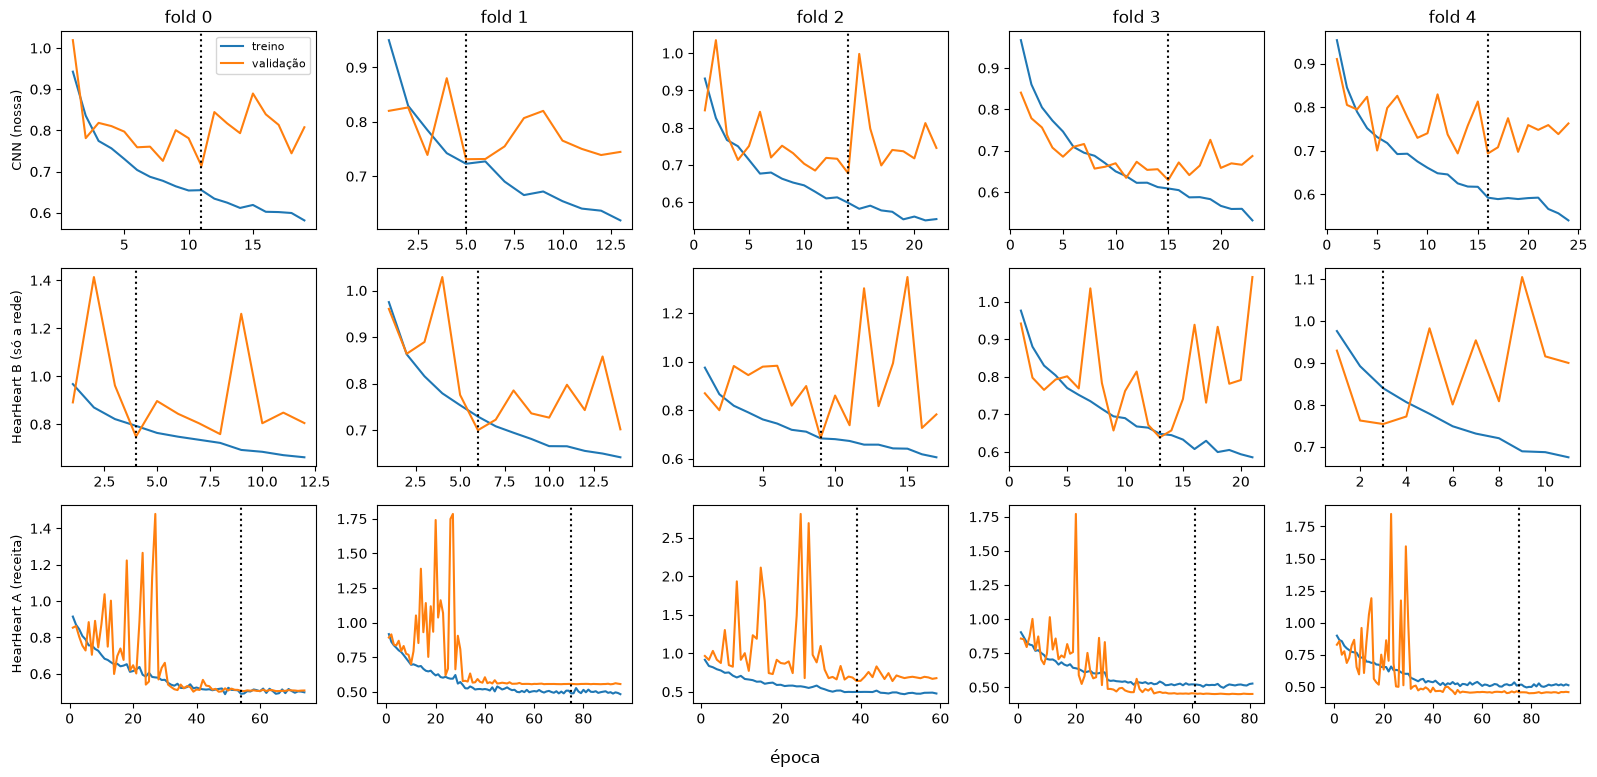

In [4]:
fig, axes = plt.subplots(len(res), 5, figsize=(16, 2.6 * len(res)), squeeze=False)
for i, (n, r) in enumerate(res.items()):
    for k, h in r['hist'].items():
        ax = axes[i, k]
        ax.plot(h.epoch + 1, h.train_loss, label='treino'); ax.plot(h.epoch + 1, h.val_loss, label='validação')
        ax.axvline(best_epoch(h) + 1, ls=':', c='k')
        if i == 0: ax.set_title(f'fold {k}')
    axes[i, 0].set_ylabel(n, fontsize=9)
axes[0, 0].legend(fontsize=8); fig.supxlabel('época'); plt.tight_layout()
pd.DataFrame({n: {'melhor época (média)': np.mean([best_epoch(h) + 1 for h in r['hist'].values()]),
                  'épocas treinadas (média)': np.mean([len(h) for h in r['hist'].values()])}
              for n, r in res.items()}).T.round(1)

**Leitura.** A receita A treina muito mais tempo (melhor época ~60): a descida da learning rate nas épocas 30 e 50
é o que a faz melhorar. A versão B, com o nosso treino (lr constante), pára cedo.

## 4. Avaliação por paciente (a nossa regra: máximo por paciente + limiares encadeados)

In [5]:
summary = pd.DataFrame({n: {'WA média': r['table']['WA (tuned)'].mean(), 'WA dp': r['table']['WA (tuned)'].std(),
                            **{f'recall {c}': r['rep']['recall'][c] for c in CLASSES}} for n, r in res.items()}).T
display(summary.round(3))
wa = pd.DataFrame({n: r['table']['WA (tuned)'] for n, r in res.items()})
display(wa.round(3))
base = 'CNN (nossa)'
pd.DataFrame({n: {'diferença média': round((wa[n] - wa[base]).mean(), 3),
                  'folds em que ganha à CNN': f"{int((wa[n] > wa[base]).sum())}/5"} for n in wa if n != base}).T

,WA média,WA dp,recall Present,recall Unknown,recall Absent
CNN (nossa),0.767,0.021,0.783,0.333,0.872
HearHeart B (só a rede),0.715,0.051,0.699,0.481,0.802
HearHeart A (receita),0.750,0.030,0.776,0.167,0.885


,CNN (nossa),HearHeart B (só a rede),HearHeart A (receita)
fold,,,
0,0.734,0.654,0.716
1,0.758,0.698,0.765
2,0.778,0.785,0.722
3,0.782,0.744,0.758
4,0.783,0.692,0.787


,diferença média,folds em que ganha à CNN
HearHeart B (só a rede),-0.052,1/5
HearHeart A (receita),-0.017,2/5


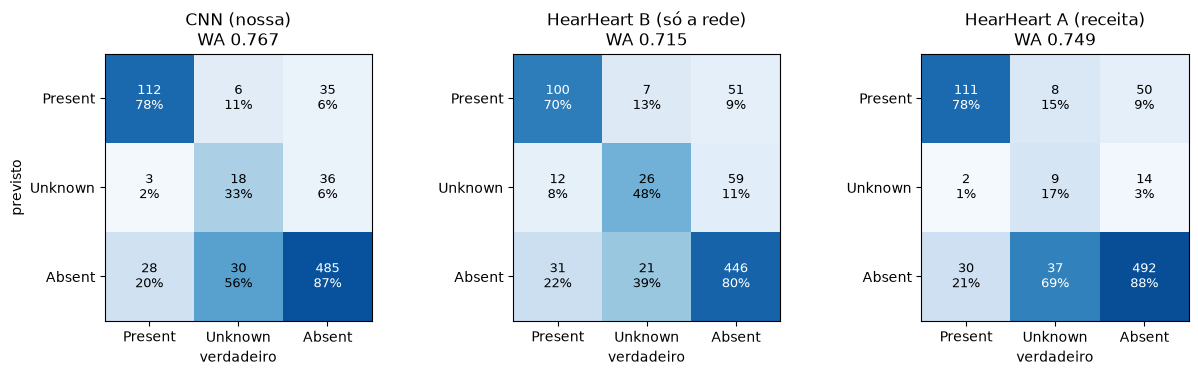

In [6]:
fig, axes = plt.subplots(1, len(res), figsize=(4.2 * len(res), 3.8))
for ax, (n, r) in zip(axes, res.items()):
    m = r['rep']['confusion']; rec = m / m.sum(0, keepdims=True)
    ax.imshow(rec, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{m[i, j]}\n{rec[i, j]:.0%}', ha='center', va='center', color='white' if rec[i, j] > .6 else 'black', fontsize=9)
    ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES, xlabel='verdadeiro',
           title=f"{n}\nWA {r['rep']['weighted_accuracy']:.3f}")
axes[0].set_ylabel('previsto'); plt.tight_layout()

## 5. Com a regra de decisão do HearHeart

O HearHeart não usa limiares: cada gravação recebe a classe mais provável e o paciente é *Absent* se todas as
gravações forem *Absent*, *Present* se alguma for *Present*, e *Unknown* nos outros casos. Aplicamos esta regra aos
três modelos para separar o efeito do modelo do efeito da regra.

In [7]:
def hh_rule(dev, oof):
    p = pd.DataFrame(oof, columns=CLASSES, index=dev.index)
    p['recording'], p['pid'], p['fold'], p['true'] = dev.recording, dev.patient_id, dev.fold, dev.murmur
    rec = p.groupby('recording').agg({**{c: 'mean' for c in CLASSES}, 'pid': 'first', 'fold': 'first', 'true': 'first'})
    rec['pred'] = np.array(CLASSES)[rec[CLASSES].to_numpy().argmax(1)]
    rule = lambda x: 'Absent' if (x == 'Absent').all() else 'Present' if (x == 'Present').any() else 'Unknown'
    pat = rec.groupby('pid').agg(fold=('fold', 'first'), true=('true', 'first'), pred=('pred', rule))
    return pd.Series({k: report(x.true, x.pred)['weighted_accuracy'] for k, x in pat.groupby('fold')})

pd.DataFrame({n: {'WA com os nossos limiares': r['table']['WA (tuned)'].mean(),
                  'WA com a regra HearHeart': hh_rule(r['dev'], r['oof']).mean()} for n, r in res.items()}).T.round(3)

,WA com os nossos limiares,WA com a regra HearHeart
CNN (nossa),0.767,0.674
HearHeart B (só a rede),0.715,0.684
HearHeart A (receita),0.750,0.763


**Leitura.** A regra deles só funciona com o treino deles: com pesos de classe 5/3/1 (os da métrica), a classe mais
provável já está ajustada à WA. Os nossos modelos treinam com pesos inversos à frequência e preveem *Unknown* em
excesso com esta regra, por isso precisam dos limiares afinados.

Atenção: na receita A, o early stopping escolhe a época com maior WA no próprio fold de validação, o que torna os
números de A ligeiramente otimistas.

## 6. Conclusões

1. **A arquitetura deles não é melhor do que a nossa:** com a mesma entrada e o mesmo treino (versão B), fica abaixo
   da nossa CNN.
2. **O que faz a diferença é a receita de treino:** a entrada mais longa, a descida da learning rate e os pesos de
   classe iguais aos da métrica levam a rede deles para perto da nossa CNN.
3. **A nossa CNN está ao nível do vencedor do Challenge:** nas mesmas condições, a receita completa do HearHeart
   não a ultrapassa (nem com a regra de decisão deles). Pela regra que definimos (só trocar se ganhar por mais de
   0.02), **fica a nossa CNN**.